# Welded beam: sign-constrained Ridge surrogate for RBDO

Single notebook for **Case Study 1** of the manuscript *Sign-Constrained Surrogate Learning for Reliability-Based Design Optimization under Limited Objective Information*. Run all cells in order (Runtime, then Run all). On Colab the full run takes a few minutes; set `QUICK_TEST = True` in the configuration cell for a fast smoke test (5 repeats, 200,000 Monte Carlo samples).

**What it reproduces**

| Section | Content | Manuscript item |
|---|---|---|
| 3 | Five-fold CV selection of the Ridge parameter, coefficient table, regularization-path sign diagnostic | coefficient table, CV R2 |
| 4 | Learning curves over 50 repeated subsets, paired Wilcoxon tests | earlier protocol, not used in the revised manuscript |
| 5 | Factorial unbundling {sign restriction on/off} x {domain-safety floor on/off}, effect sizes | earlier protocol, not used in the revised manuscript |
| 6 | Learning-curve figure | earlier protocol, not used in the revised manuscript |
| 7 | RBDO with the learned objective, FORM (Abdo-Rackwitz, OpenTURNS) and multi-start COBYLA | RBDO tables |
| 8 | Monte Carlo verification of FORM, 2,000,000 samples per constraint, Wilson 95% intervals | Monte Carlo table |

**Conventions.** Cross-validated R2 is scored against the noisy training labels. Learning-curve R2 is scored on an independent noise-free test set of 2,000 Latin-hypercube points. The fold standard deviation is the population standard deviation over the five folds (`ddof=0`). All random number generators use fixed seeds.

> **Scope in the revised manuscript.** Sections that give the full-sample fits, the coefficient tables, the RBDO designs and the Monte Carlo verification of FORM are the source of the corresponding tables of the manuscript. The learning-curve sections of this notebook (50 repeated subsets of one 300-label pool, with the regularization strength chosen on the full pool) are the **earlier protocol**. They are kept for transparency, and **no number of the revised manuscript comes from them**. All learning-curve, noise, label-count, small-sample RBDO and statistical results of the revised manuscript come from `replicated_experiments.ipynb` (independent replicates, regularization chosen inside each training set).

In [1]:
# pip skipped in sandbox

## 1. Setup and configuration

In [2]:
import os, time, warnings, itertools, zipfile
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, Bounds, LinearConstraint
from scipy.stats import qmc, norm, wilcoxon
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import openturns as ot

warnings.filterwarnings("ignore")
ot.Log.Show(ot.Log.NONE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [3]:
# ---------- statistics helpers ----------
def wilson_interval(k, n, z=1.959964):
    """Wilson score 95% interval for a binomial proportion k/n."""
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0.0, centre - half), centre + half


def hodges_lehmann(d):
    """Hodges-Lehmann one-sample estimator: median of Walsh averages."""
    w = (d[:, None] + d[None, :]) / 2.0
    return float(np.median(w[np.triu_indices(len(d))]))


def paired_summary(a, b, n_boot=500, seed=1, tol=1e-6):
    """Paired comparison a - b.

    Returns the mean difference, the Hodges-Lehmann estimate with a bootstrap 95% CI, the number of
    repeats where a > b, and a paired Wilcoxon p-value. Differences smaller than `tol` in absolute value
    are treated as exact zeros for the Wilcoxon test: they are solver noise (about 1e-9), and ranking
    them would otherwise make the p-value depend on numerical noise rather than on the data.
    """
    d = np.asarray(a, float) - np.asarray(b, float)
    rng = np.random.default_rng(seed)
    boots = [hodges_lehmann(rng.choice(d, len(d))) for _ in range(n_boot)]
    d_test = np.where(np.abs(d) < tol, 0.0, d)
    try:
        p = float(wilcoxon(d_test).pvalue)
    except ValueError:  # every difference is (numerically) zero
        p = float("nan")
    return {"mean_diff": d.mean(), "HL": hodges_lehmann(d),
            "HL_lo": np.percentile(boots, 2.5), "HL_hi": np.percentile(boots, 97.5),
            "wins": int((d > tol).sum()), "n_nonzero": int((np.abs(d) >= tol).sum()), "p_wilcoxon": p}

In [4]:
# ---------- configuration ----------
QUICK_TEST = False            # True: 5 repeats and 200k Monte Carlo samples (smoke test only)

SEED = 42
N_BASE, N_TEST = 300, 2000
NOISE_FRAC = 0.15             # label noise: sd = 15% of the true value (heteroscedastic)
SAMPLE_SIZES = [20, 50, 100, 200, 300]
N_REPEATS = 5 if QUICK_TEST else 50
N_MC = 200_000 if QUICK_TEST else 2_000_000
ALPHA_GRID = np.logspace(-4, 4, 100)
PF_TARGET = 0.01
BETA_TARGET = -norm.ppf(PF_TARGET)           # 2.3263

RESULTS_DIR = "results_welded_beam"
os.makedirs(RESULTS_DIR, exist_ok=True)
SAVED_TABLES = {}

print("QUICK_TEST:", QUICK_TEST, "| repeats:", N_REPEATS, "| MC samples:", N_MC)
print("OpenTURNS", ot.__version__, "| beta target %.4f" % BETA_TARGET)

QUICK_TEST: False | repeats: 50 | MC samples: 2000000
OpenTURNS 1.27.post1 | beta target 2.3263


## 2. Problem definition and data

Design variables: weld throat thickness $x_1$, weld length $x_2$, beam depth $x_3$, beam width $x_4$ (inches). The cost is minimized subject to four probabilistic limit states and the deterministic rule $x_4 \ge x_1$. The applied load $P \sim \mathcal{N}(6000, 600)$ and Young's modulus $E \sim \mathcal{N}(30\times10^6, 3\times10^6)$ are the only random variables; the shear modulus $G = 12\times10^6$ psi is a fixed constant. Failure is $G_i \le 0$.

In [5]:
LOWER = np.array([0.1, 0.1, 0.1, 0.1])
UPPER = np.array([2.0, 10.0, 10.0, 2.0])

L_BEAM, G_SHEAR = 14.0, 12.0e6
TAU_MAX, SIGMA_MAX, DELTA_MAX = 13_600.0, 30_000.0, 0.25
P_MEAN, P_SD = 6000.0, 600.0
E_MEAN, E_SD = 30.0e6, 3.0e6


def cost_true(X):
    """Analytical fabrication cost (used only to generate labels and to validate designs)."""
    X = np.atleast_2d(np.asarray(X, float))
    x1, x2, x3, x4 = X.T
    return 1.10471 * x1**2 * x2 + 0.04811 * x3 * x4 * (14.0 + x2)


def limit_states(P, E, x1, x2, x3, x4):
    """Safety margins G1..G4 (failure when <= 0). Works for scalars or NumPy arrays."""
    tau1 = P / (np.sqrt(2.0) * x1 * x2)
    M = P * (L_BEAM + x2 / 2.0)
    R = np.sqrt(x2**2 / 4.0 + ((x1 + x3) / 2.0) ** 2)
    # Polar moment of the two fillet-weld throats about the weld-group centroid:
    # J = 2 * A_w * (x2^2/12 + d^2), A_w = x1*x2/sqrt(2), d = (x1 + x3)/2  (manuscript Appendix A).
    J = np.sqrt(2.0) * x1 * x2 * (x2**2 / 12.0 + ((x1 + x3) / 2.0) ** 2)
    tau2 = M * R / J
    tau = np.sqrt(tau1**2 + 2.0 * tau1 * tau2 * x2 / (2.0 * R) + tau2**2)
    Pc = 4.013 * E * np.sqrt(x3**2 * x4**6 / 36.0) / L_BEAM**2 * (1.0 - x3 / (2.0 * L_BEAM) * np.sqrt(E / (4.0 * G_SHEAR)))
    return {
        "G1": TAU_MAX - tau,                                        # weld shear
        "G2": SIGMA_MAX - 6.0 * P * L_BEAM / (x4 * x3**2),          # bending
        "G3": DELTA_MAX - 4.0 * P * L_BEAM**3 / (E * x4 * x3**3),   # tip deflection
        "G4": Pc - P,                                               # buckling
    }
CONSTRAINTS = ["G1", "G2", "G3", "G4"]


def make_training_data(seed=SEED):
    X = qmc.scale(qmc.LatinHypercube(d=4, seed=seed).random(N_BASE), LOWER, UPPER)
    y_true = cost_true(X)
    rng = np.random.default_rng(seed)
    return X, y_true + rng.normal(0.0, NOISE_FRAC * np.abs(y_true))


def make_test_data(seed=SEED + 1000):
    X = qmc.scale(qmc.LatinHypercube(d=4, seed=seed).random(N_TEST), LOWER, UPPER)
    return X, cost_true(X)


X_base, y_base = make_training_data()
X_test, y_test = make_test_data()
print("training labels:", len(y_base), "| test points:", len(y_test))
print("noisy cost range %.3f to %.3f" % (y_base.min(), y_base.max()))

training labels: 300 | test points: 2000
noisy cost range 0.230 to 70.151


## 3. Models and full-sample fits

`StandardizedRidge` is a Ridge regression on standardized features with two optional constraints:

* `sign=True`: all four slopes are non-negative (the prescribed causal signs).
* `floor=True`: the predicted cost must be non-negative everywhere in the design box. A linear predictor attains its minimum at a corner, so this is a set of linear inequalities in the coefficients and intercept. With the sign restriction on, only the lower corner can be binding. With it off, all 16 corners are imposed. The constrained problem is a convex quadratic program solved with SciPy `trust-constr` using the exact Hessian.

The estimator named *sign-constrained* in the manuscript is `sign=True, floor=False` (sign restriction only). The floor variant is reported only in the factorial of Section 5. The *shrinkage-matched* baseline is `sign=False, floor=False` fitted at the sign-constrained model's selected $\alpha$.

In [6]:
CORNERS = np.array(list(itertools.product(*[(LOWER[i], UPPER[i]) for i in range(4)])))


class StandardizedRidge(BaseEstimator, RegressorMixin):
    """Ridge on standardized features with optional sign restriction and domain-safety floor."""

    def __init__(self, alpha=1.0, sign=False, floor=False):
        self.alpha, self.sign, self.floor = alpha, sign, floor

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        n, p = X.shape
        self.scaler_ = StandardScaler().fit(X)
        Xs = self.scaler_.transform(X)
        if not self.sign and not self.floor:
            m = Ridge(alpha=self.alpha).fit(Xs, y)
            w, b = m.coef_, m.intercept_
        elif self.sign and not self.floor:
            m = Ridge(alpha=self.alpha, positive=True, solver="lbfgs", max_iter=50000, tol=1e-12).fit(Xs, y)
            w, b = m.coef_, m.intercept_
        else:
            corners = LOWER.reshape(1, -1) if self.sign else CORNERS
            A = np.c_[self.scaler_.transform(corners), np.ones(len(corners))]
            fun = lambda t: float((y - Xs @ t[:-1] - t[-1]) @ (y - Xs @ t[:-1] - t[-1]) + self.alpha * (t[:-1] @ t[:-1]))
            jac = lambda t: np.r_[-2 * Xs.T @ (y - Xs @ t[:-1] - t[-1]) + 2 * self.alpha * t[:-1], -2 * (y - Xs @ t[:-1] - t[-1]).sum()]
            H = np.zeros((p + 1, p + 1))
            H[:p, :p] = 2 * Xs.T @ Xs + 2 * self.alpha * np.eye(p)
            H[:p, p] = H[p, :p] = 2 * Xs.sum(axis=0)
            H[p, p] = 2 * n
            lo = np.r_[np.zeros(p) if self.sign else np.full(p, -np.inf), -np.inf]
            res = minimize(fun, np.r_[np.zeros(p), max(y.mean(), 0.0)], jac=jac, hess=lambda _: H,
                           method="trust-constr", bounds=Bounds(lo, np.full(p + 1, np.inf)),
                           constraints=[LinearConstraint(A, 0.0, np.inf)],
                           options={"maxiter": 2000, "gtol": 1e-8, "xtol": 1e-10})
            w, b = res.x[:-1], res.x[-1]
        self.coef_ = w / self.scaler_.scale_
        self.intercept_ = float(b - np.sum(w * self.scaler_.mean_ / self.scaler_.scale_))
        return self

    def predict(self, X):
        return np.asarray(X, float) @ self.coef_ + self.intercept_

    def corner_value(self):
        return float(self.predict(LOWER.reshape(1, -1))[0])


def select_alpha(sign, floor):
    cv = KFold(5, shuffle=True, random_state=SEED)
    gs = GridSearchCV(StandardizedRidge(sign=sign, floor=floor), {"alpha": ALPHA_GRID}, cv=cv, scoring="r2")
    gs.fit(X_base, y_base)
    return float(gs.best_params_["alpha"]), float(gs.best_score_)


def fold_scores(alpha, sign, floor):
    cv = KFold(5, shuffle=True, random_state=SEED)
    s = cross_val_score(StandardizedRidge(alpha, sign, floor), X_base, y_base, cv=cv, scoring="r2")
    return s.mean(), s.std(ddof=0)


t0 = time.time()
alpha_u, cvr2_u = select_alpha(sign=False, floor=False)      # unrestricted Ridge
alpha_c, cvr2_c = select_alpha(sign=True, floor=False)       # sign-constrained (sign restriction only)
m_u = StandardizedRidge(alpha_u, False, False).fit(X_base, y_base)
m_c = StandardizedRidge(alpha_c, True, False).fit(X_base, y_base)
m_s = StandardizedRidge(alpha_c, False, False).fit(X_base, y_base)   # shrinkage-matched
print("selected alpha: unrestricted %.4f | sign-constrained %.4f   (%.0f s)" % (alpha_u, alpha_c, time.time() - t0))

rows = []
for name, m, a, sg, fl in [("Unrestricted Ridge", m_u, alpha_u, False, False),
                           ("Sign-constrained Ridge", m_c, alpha_c, True, False),
                           ("Shrinkage-matched (alpha = alpha_c)", m_s, alpha_c, False, False)]:
    mean, sd = fold_scores(a, sg, fl)
    rows.append({"Model": name, "alpha": a, "CV R2 mean": mean, "CV R2 fold sd": sd,
                 "Test R2 (300 labels)": r2_score(y_test, m.predict(X_test))})
full_table = pd.DataFrame(rows)
SAVED_TABLES["wb_full_sample_performance.csv"] = full_table
display(full_table.round(4))

coef_table = pd.DataFrame({
    "Variable": ["x1", "x2", "x3", "x4"],
    "Unrestricted": m_u.coef_, "Sign-constrained": m_c.coef_, "Shrinkage-matched": m_s.coef_})
coef_table["Binding?"] = np.where(m_u.coef_ < -1e-8, "Yes", "No")
SAVED_TABLES["wb_coefficients.csv"] = coef_table
display(coef_table.round(3))
print("Predicted cost at the lower design corner (sign-constrained fit): %.3e" % m_c.corner_value())
print("Predicted cost at the lower design corner (unrestricted fit):     %.3f" % m_u.corner_value())

selected alpha: unrestricted 8.4975 | sign-constrained 8.4975   (3 s)


,Model,alpha,CV R2 mean,CV R2 fold sd,Test R2 (300 labels)
0,Unrestricted Ridge,8.4975,0.7264,0.0502,0.8184
1,Sign-constrained Ridge,8.4975,0.7264,0.0502,0.8184
2,Shrinkage-matched (alpha = alpha_c),8.4975,0.7264,0.0502,0.8184


,Variable,Unrestricted,Sign-constrained,Shrinkage-matched,Binding?
0,x1,11.154,11.154,11.154,No
1,x2,1.751,1.751,1.751,No
2,x3,0.891,0.891,0.891,No
3,x4,5.351,5.351,5.351,No


Predicted cost at the lower design corner (sign-constrained fit): -1.623e+01
Predicted cost at the lower design corner (unrestricted fit):     -16.230


**Regularization-path diagnostic.** The sign restriction can only change the unrestricted fit if some unrestricted coefficient turns negative at some $\alpha$. The check below fits the unrestricted model at every $\alpha$ of the grid.

In [7]:
neg_counts = 0
min_coef = np.inf
for a in ALPHA_GRID:
    c = StandardizedRidge(a, False, False).fit(X_base, y_base).coef_
    min_coef = min(min_coef, c.min())
    neg_counts += int((c < 0).any())
print("grid points with any negative unrestricted coefficient: %d of %d" % (neg_counts, len(ALPHA_GRID)))
print("smallest unrestricted coefficient anywhere on the grid: %.4f" % min_coef)

grid points with any negative unrestricted coefficient: 0 of 100
smallest unrestricted coefficient anywhere on the grid: 0.0158


## 4. Learning curves (50 repeated subsets) (earlier protocol, not used in the manuscript)

For each reduced size the same resampled subset is used by every model within a repeat, so all comparisons are paired. Each model keeps the regularization strength selected on the full 300-label set, so differences across sample sizes are not confounded by re-selecting $\alpha$. The 300-label case is a single fit on the whole pool. All models are scored on the independent noise-free test set.

The eight cells below cover the three models of the main learning-curve table (unrestricted at $\alpha_u$, sign-constrained and shrinkage-matched at $\alpha_c$) and the factorial of Section 5 at both $\alpha_c$ and $\alpha_u$.

In [8]:
CELLS = {   # name: (alpha, sign, floor)
    "Unrestricted":                       (alpha_u, False, False),
    "Sign-constrained":                   (alpha_c, True,  False),
    "ac: sign on,  floor on":             (alpha_c, True,  True),
    "Shrinkage-matched":                  (alpha_c, False, False),
    "ac: sign on,  floor off":            (alpha_c, True,  False),
    "ac: sign off, floor on":             (alpha_c, False, True),
    "au: sign on,  floor off":            (alpha_u, True,  False),
    "au: sign off, floor on":             (alpha_u, False, True),
    "au: sign on,  floor on":             (alpha_u, True,  True),
}
rng = np.random.default_rng(SEED + 200)
records = []
t0 = time.time()
for n in SAMPLE_SIZES:
    for rep in range(1 if n == N_BASE else N_REPEATS):
        idx = np.arange(N_BASE) if n == N_BASE else rng.choice(N_BASE, size=n, replace=False)
        for name, (a, sg, fl) in CELLS.items():
            m = StandardizedRidge(a, sg, fl).fit(X_base[idx], y_base[idx])
            records.append({"n": n, "rep": rep, "cell": name,
                            "R2": r2_score(y_test, m.predict(X_test)), "corner": m.corner_value()})
lc = pd.DataFrame(records)
print("learning curves done in %.0f s" % (time.time() - t0))

def mean_table(names):
    t = lc[lc.cell.isin(names)].pivot_table(index="n", columns="cell", values="R2")[names]
    return t

main = mean_table(["Unrestricted", "Sign-constrained", "Shrinkage-matched"])
pvals = {}
for n in SAMPLE_SIZES[:-1]:
    a = lc[(lc.n == n) & (lc.cell == "Unrestricted")].sort_values("rep").R2.values
    b = lc[(lc.n == n) & (lc.cell == "Sign-constrained")].sort_values("rep").R2.values
    pvals[n] = paired_summary(a, b)["p_wilcoxon"]
main["Wilcoxon p (unrestricted vs sign-constrained)"] = pd.Series(pvals)
SAVED_TABLES["wb_learning_curve_table.csv"] = main.reset_index()
display(main.style.format({"Unrestricted": "{:.4f}", "Sign-constrained": "{:.4f}", "Shrinkage-matched": "{:.4f}", "Wilcoxon p (unrestricted vs sign-constrained)": "{:.2e}"}, na_rep="--"))

learning curves done in 20 s


cell,Unrestricted,Sign-constrained,Shrinkage-matched,Wilcoxon p (unrestricted vs sign-constrained)
n,,,,
20,0.6772,0.6772,0.6772,--
50,0.7680,0.7680,0.7680,--
100,0.8004,0.8004,0.8004,--
200,0.8145,0.8145,0.8145,--
300,0.8184,0.8184,0.8184,--


## 5. Factorial unbundling: sign restriction versus domain-safety floor (earlier protocol, not used in the manuscript)

The sign-constrained estimator bundles two constraints. This section separates them: all four cells are fitted at the same $\alpha$, on the same 50 subsets and the same test set. A floor-constraint activation is counted when the predicted lower-corner cost is zero to within $10^{-4}$. In the paired tests, differences below $10^{-6}$ in R2 are treated as zero (solver noise); `n_nonzero` counts the repeats that differ by more than that.

In [9]:
fact_names = ["Shrinkage-matched", "ac: sign on,  floor off", "ac: sign off, floor on", "ac: sign on,  floor on"]
fact_ac = mean_table(fact_names)
fact_ac.columns = ["sign off, floor off", "sign on, floor off", "sign off, floor on", "sign on, floor on"]
print("Mean test R2 with all four cells at alpha = alpha_c = %.2f" % alpha_c)
display(fact_ac.round(4))

fact_au = mean_table(["Unrestricted", "au: sign on,  floor off", "au: sign off, floor on", "au: sign on,  floor on"])
fact_au.columns = fact_ac.columns
print("Robustness: all four cells at alpha = alpha_u = %.2f" % alpha_u)
display(fact_au.round(4))
SAVED_TABLES["wb_unbundling_alpha_c.csv"] = fact_ac.reset_index()
SAVED_TABLES["wb_unbundling_alpha_u.csv"] = fact_au.reset_index()

act = (lc[lc.cell == "ac: sign on,  floor on"].assign(active=lambda t: t.corner < 1e-4)
         .groupby("n").agg(mean_corner=("corner", "mean"), share_floor_active=("active", "mean")))
print("Floor-constraint activation of the sign-plus-floor model")
display(act.round(3))

def contrast(a_name, b_name, label):
    out = []
    for n in SAMPLE_SIZES[:-1]:
        a = lc[(lc.n == n) & (lc.cell == a_name)].sort_values("rep").R2.values
        b = lc[(lc.n == n) & (lc.cell == b_name)].sort_values("rep").R2.values
        s = paired_summary(a, b); s.update({"contrast": label, "n": n}); out.append(s)
    return pd.DataFrame(out)[["contrast", "n", "mean_diff", "HL", "HL_lo", "HL_hi", "n_nonzero", "p_wilcoxon"]]

effects = pd.concat([
    contrast("ac: sign off, floor on", "Shrinkage-matched", "floor on minus off (sign off)"),
    contrast("ac: sign on,  floor on", "ac: sign on,  floor off", "floor on minus off (sign on)"),
    contrast("ac: sign on,  floor off", "Shrinkage-matched", "sign on minus off (floor off)"),
    contrast("ac: sign on,  floor on", "ac: sign off, floor on", "sign on minus off (floor on)"),
    contrast("Shrinkage-matched", "Sign-constrained", "shrinkage-matched minus sign-constrained"),
])
SAVED_TABLES["wb_unbundling_effects.csv"] = effects
display(effects.style.format({"mean_diff": "{:.4f}", "HL": "{:.4f}", "HL_lo": "{:.4f}", "HL_hi": "{:.4f}", "p_wilcoxon": "{:.2e}"}, na_rep="all equal"))

Mean test R2 with all four cells at alpha = alpha_c = 8.50


,"sign off, floor off","sign on, floor off","sign off, floor on","sign on, floor on"
n,,,,
20,0.6772,0.6772,0.5192,0.5192
50,0.7680,0.7680,0.5756,0.5756
100,0.8004,0.8004,0.5931,0.5931
200,0.8145,0.8145,0.6015,0.6015
300,0.8184,0.8184,0.6055,0.6055


Robustness: all four cells at alpha = alpha_u = 8.50


,"sign off, floor off","sign on, floor off","sign off, floor on","sign on, floor on"
n,,,,
20,0.6772,0.6772,0.5192,0.5192
50,0.7680,0.7680,0.5756,0.5756
100,0.8004,0.8004,0.5931,0.5931
200,0.8145,0.8145,0.6015,0.6015
300,0.8184,0.8184,0.6055,0.6055


Floor-constraint activation of the sign-plus-floor model


,mean_corner,share_floor_active
n,,
20,0.0,1.00
50,0.0,0.98
100,0.0,1.00
200,0.0,1.00
300,0.0,1.00


,contrast,n,mean_diff,HL,HL_lo,HL_hi,n_nonzero,p_wilcoxon
0,floor on minus off (sign off),20,-0.1580,-0.1526,-0.1723,-0.1362,50,1.78e-15
1,floor on minus off (sign off),50,-0.1924,-0.1934,-0.1985,-0.1883,50,1.78e-15
2,floor on minus off (sign off),100,-0.2072,-0.2077,-0.2102,-0.2052,50,1.78e-15
3,floor on minus off (sign off),200,-0.2130,-0.2131,-0.2136,-0.2125,50,1.78e-15
0,floor on minus off (sign on),20,-0.1580,-0.1526,-0.1723,-0.1362,50,1.78e-15
1,floor on minus off (sign on),50,-0.1924,-0.1934,-0.1985,-0.1883,50,1.78e-15
2,floor on minus off (sign on),100,-0.2072,-0.2077,-0.2102,-0.2052,50,1.78e-15
3,floor on minus off (sign on),200,-0.2130,-0.2131,-0.2136,-0.2125,50,1.78e-15
0,sign on minus off (floor off),20,-0.0000,-0.0000,-0.0000,0.0000,0,all equal
1,sign on minus off (floor off),50,-0.0000,-0.0000,-0.0000,0.0000,0,all equal


## 6. Learning-curve figure (earlier protocol, not used in the manuscript)

Line styles and markers differ between models so the figure is readable in grayscale and for readers with color-vision deficiency.

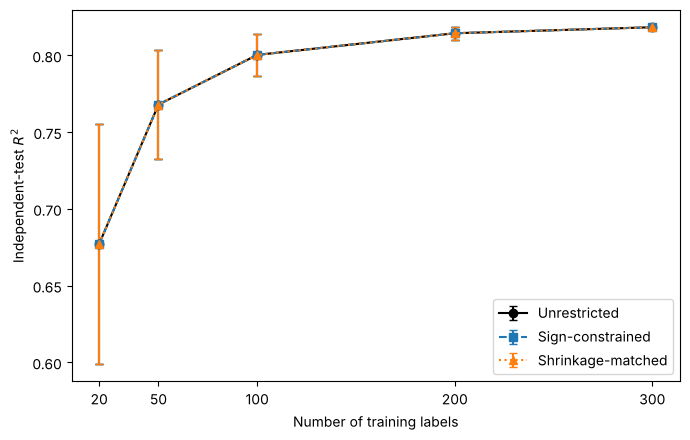

In [10]:
styles = {"Unrestricted": ("o", "-"), "Sign-constrained": ("s", "--"), "Shrinkage-matched": ("^", ":")}
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, (mk, ls) in styles.items():
    d = lc[lc.cell == name].groupby("n").R2.agg(["mean", "std"]).reset_index()
    ax.errorbar(d.n, d["mean"], yerr=d["std"].fillna(0), marker=mk, linestyle=ls, capsize=3, color="black" if name == "Unrestricted" else None, label=name)
ax.set_xlabel("Number of training labels"); ax.set_ylabel("Independent-test $R^2$")
ax.set_xticks(SAMPLE_SIZES); ax.legend(); fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "FigureLC_WB_v3.png"), dpi=300, bbox_inches="tight")
plt.show()

## 7. RBDO with FORM and multi-start COBYLA

The learned surrogate is used only for the objective. Each probabilistic constraint is evaluated by FORM (Abdo-Rackwitz algorithm in OpenTURNS) on the original limit states, with the requirement $\beta_i \ge \beta_T = 2.326$ ($P_f \le 0.01$), plus $x_4 \ge x_1$. Design variables are normalized to $[0,1]^4$. If a FORM run fails to converge it is retried from shifted starting points, and if all retries fail the point is treated as infeasible by returning $\beta = -10$. COBYLA is run from every FORM-feasible starting point and the best feasible result (lowest value of the optimized objective) is kept.

In [11]:
def _g_fun(key):
    def f(v):
        P, E, x1, x2, x3, x4 = v
        return [float(limit_states(P, E, x1, x2, x3, x4)[key])]
    return ot.PythonFunction(6, 1, f)
OT_G = {k: _g_fun(k) for k in CONSTRAINTS}
FORM_STARTS = [[P_MEAN, E_MEAN], [P_MEAN, E_MEAN - E_SD], [P_MEAN + P_SD, E_MEAN],
               [P_MEAN - P_SD, E_MEAN], [P_MEAN, E_MEAN + E_SD], [P_MEAN + 2 * P_SD, E_MEAN - E_SD]]


@lru_cache(maxsize=None)
def _form_cached(key, x_rounded):
    joint = ot.JointDistribution([ot.Normal(P_MEAN, P_SD), ot.Normal(E_MEAN, E_SD)])
    fixed = ot.ParametricFunction(OT_G[key], [2, 3, 4, 5], ot.Point(list(x_rounded)))
    event = ot.ThresholdEvent(ot.CompositeRandomVector(fixed, ot.RandomVector(joint)), ot.LessOrEqual(), 0.0)
    for start in FORM_STARTS:
        try:
            algo = ot.FORM(ot.AbdoRackwitz(), event, ot.Point(start)); algo.run()
            r = algo.getResult()
            return float(r.getEventProbability()), float(r.getGeneralisedReliabilityIndex())
        except RuntimeError:
            continue
    return 1.0, -10.0


def form(x):
    key = tuple(np.round(np.asarray(x, float), 8))
    return {k: _form_cached(k, key) for k in CONSTRAINTS}

to_x = lambda z: LOWER + np.asarray(z) * (UPPER - LOWER)
to_z = lambda x: (np.asarray(x) - LOWER) / (UPPER - LOWER)

def is_feasible(x, tol=1e-5):
    f = form(x)
    return all(f[k][1] >= BETA_TARGET - tol for k in CONSTRAINTS) and x[3] >= x[0] - 1e-8


def solve_rbdo(objective, starts, rhobeg=0.10, tol=1e-8, maxiter=5000):
    cons = [{"type": "ineq", "fun": (lambda z, j=j: z[j])} for j in range(4)]
    cons += [{"type": "ineq", "fun": (lambda z, j=j: 1.0 - z[j])} for j in range(4)]
    cons += [{"type": "ineq", "fun": (lambda z, k=k: form(to_x(z))[k][1] - BETA_TARGET)} for k in CONSTRAINTS]
    cons += [{"type": "ineq", "fun": lambda z: to_x(z)[3] - to_x(z)[0]}]
    best = None
    for x0 in starts:
        r = minimize(lambda z: objective(to_x(z)), to_z(x0), method="COBYLA", constraints=cons,
                     options={"maxiter": maxiter, "rhobeg": rhobeg, "tol": tol, "catol": 1e-6})
        x = to_x(r.x)
        if is_feasible(x) and (best is None or objective(x) < best[1]):
            best = (x, objective(x))
    return best


# FORM-feasible starting points, taken from a fixed candidate list
candidates = [np.array(c) for c in ([0.30, 7.0, 9.0, 0.40], [0.303, 8.197, 9.246, 0.303], [0.344, 8.032, 9.232, 0.37],
                                    [0.24, 6.5, 8.0, 0.35], [0.35, 5.0, 9.5, 0.45], [0.30, 8.0, 9.5, 0.40])]
starts = [c for c in candidates if is_feasible(c)]
print("FORM-feasible starting points:", len(starts))
for s in starts:
    print("  ", np.round(s, 3), {k: round(v[1], 2) for k, v in form(s).items()})
assert starts, "no feasible starting point found: extend the candidate list"

FORM-feasible starting points: 3
   [0.3 7.  9.  0.4] {'G1': 4.53, 'G2': 9.29, 'G3': 9.69, 'G4': 8.83}
   [0.303 8.197 9.246 0.303] {'G1': 6.86, 'G2': 5.42, 'G3': 9.63, 'G4': 7.08}
   [0.344 8.032 9.232 0.37 ] {'G1': 8.91, 'G2': 8.77, 'G3': 9.69, 'G4': 8.52}


In [12]:
surrogates = {
    "Full information": lambda x: float(cost_true(np.asarray(x).reshape(1, -1))[0]),
    "Unrestricted Ridge": lambda x: float(m_u.predict(np.asarray(x).reshape(1, -1))[0]),
    "Sign-constrained Ridge": lambda x: float(m_c.predict(np.asarray(x).reshape(1, -1))[0]),
}
t0 = time.time()
rbdo_rows, designs = [], {}
for name, obj in surrogates.items():
    x, val = solve_rbdo(obj, starts)
    f = form(x); designs[name] = x
    rbdo_rows.append({"Method": name, "x1": x[0], "x2": x[1], "x3": x[2], "x4": x[3],
                      "Surrogate objective": val, "True cost": float(cost_true(x.reshape(1, -1))[0]),
                      **{"beta_" + k: f[k][1] for k in CONSTRAINTS}, "x4 - x1": x[3] - x[0]})
    print("%-24s done (%.0f s)" % (name, time.time() - t0))
rbdo = pd.DataFrame(rbdo_rows)
SAVED_TABLES["wb_rbdo_results.csv"] = rbdo
display(rbdo.round(4))

Full information         done (2 s)


Unrestricted Ridge       done (10 s)


Sign-constrained Ridge   done (18 s)


,Method,x1,x2,x3,x4,Surrogate objective,True cost,beta_G1,beta_G2,beta_G3,beta_G4,x4 - x1
0,Full information,0.2245,7.7492,9.6036,0.2245,2.6878,2.6878,2.3263,2.3263,9.5492,2.3263,0.0
1,Unrestricted Ridge,0.4389,3.8127,8.0569,0.4389,2.9574,3.8422,2.3263,6.9604,9.6105,9.0342,0.0
2,Sign-constrained Ridge,0.4388,3.8136,8.0588,0.4388,2.9579,3.8415,2.3263,6.9618,9.6106,9.0333,0.0


## 8. Monte Carlo verification of FORM

At each final design, $P$ and $E$ are sampled directly (independent normals) and the original limit states are evaluated on every sample. The table reports the FORM failure probability, the Monte Carlo estimate, the Wilson 95% interval, and the number of observed failures. Constraints with $\beta \gtrsim 5$ have failure probabilities that this sample size cannot resolve, so zero observed failures is consistent with, but not a tight confirmation of, the FORM value.

In [13]:
rng_mc = np.random.default_rng(SEED + 2026)
P_s = rng_mc.normal(P_MEAN, P_SD, N_MC)
E_s = rng_mc.normal(E_MEAN, E_SD, N_MC)
mc_rows = []
for name, x in designs.items():
    g = limit_states(P_s, E_s, *x)
    f = form(x)
    for k in CONSTRAINTS:
        fails = int((g[k] <= 0).sum()); lo, hi = wilson_interval(fails, N_MC)
        mc_rows.append({"Design": name, "Constraint": k, "beta_FORM": f[k][1], "pf_FORM": f[k][0],
                        "pf_MC": fails / N_MC, "CI_low": lo, "CI_high": hi, "Failures": fails,
                        "FORM inside CI": lo <= f[k][0] <= hi})
mc = pd.DataFrame(mc_rows)
SAVED_TABLES["wb_monte_carlo_verification.csv"] = mc
with pd.option_context("display.float_format", "{:.3e}".format):
    display(mc)

,Design,Constraint,beta_FORM,pf_FORM,pf_MC,CI_low,CI_high,Failures,FORM inside CI
0,Full information,G1,2.326e+00,1.000e-02,9.924e-03,9.788e-03,1.006e-02,19848,True
1,Full information,G2,2.326e+00,1.000e-02,9.924e-03,9.788e-03,1.006e-02,19848,True
2,Full information,G3,9.549e+00,6.537e-22,0.000e+00,0.000e+00,1.921e-06,0,True
3,Full information,G4,2.326e+00,1.000e-02,1.010e-02,9.962e-03,1.024e-02,20200,True
4,Unrestricted Ridge,G1,2.326e+00,1.000e-02,9.924e-03,9.788e-03,1.006e-02,19848,True
5,Unrestricted Ridge,G2,6.960e+00,1.696e-12,0.000e+00,0.000e+00,1.921e-06,0,True
6,Unrestricted Ridge,G3,9.610e+00,3.610e-22,0.000e+00,0.000e+00,1.921e-06,0,True
7,Unrestricted Ridge,G4,9.034e+00,8.258e-20,0.000e+00,0.000e+00,1.921e-06,0,True
8,Sign-constrained Ridge,G1,2.326e+00,1.000e-02,9.924e-03,9.788e-03,1.006e-02,19848,True
9,Sign-constrained Ridge,G2,6.962e+00,1.680e-12,0.000e+00,0.000e+00,1.921e-06,0,True


## 9. Save results

In [14]:
# ---------- save everything and offer a download in Colab ----------
def save_table(df, name, index=False):
    path = os.path.join(RESULTS_DIR, name)
    df.to_csv(path, index=index)
    return path

for _name, _df in SAVED_TABLES.items():
    save_table(_df, _name)
zip_path = RESULTS_DIR.rstrip("/") + ".zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for _f in sorted(os.listdir(RESULTS_DIR)):
        zf.write(os.path.join(RESULTS_DIR, _f), _f)
print("Saved", len(os.listdir(RESULTS_DIR)), "files to", RESULTS_DIR, "and", zip_path)
try:
    from google.colab import files  # only available inside Colab
    files.download(zip_path)
except Exception:
    pass

Saved 9 files to results_welded_beam and results_welded_beam.zip


**Reproducibility notes.** Seeds: training design `SEED`, test design `SEED + 1000`, subset resampling `SEED + 200`, Monte Carlo `SEED + 2026`. Library versions can change the last digits of solver-based quantities (for example the constrained fits and COBYLA end points) but not the structure of the results.